<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-01-automl.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "AutoML"
bibliography:
  - refs/refs.bib
---

# The Problem: Hyperparameter Optimization

![Optimizer proposes a configuration; the learning system trains and validates it and returns a loss. Source: Hutter and Vanschoren AutoML tutorial.](img/hpo.png)

# The Problem: Hyperparameter Optimization

A learning algorithm fits **parameters** (for example, regression coefficients) from data.

**Hyperparameters** configure that fitting process: regularization strength, tree depth, or learning rate. We must choose them before fitting each candidate.

Given training data $D_{\mathrm{tr}}$, a fixed learning algorithm $A$, and a search space $\Lambda$, hyperparameter optimization (HPO) solves

$$\lambda^* \in \arg\min_{\lambda\in\Lambda} f(\lambda), \qquad
f(\lambda)=\mathcal{L}_{D_{\mathrm{val}}}\!\left(A_\lambda(D_{\mathrm{tr}})\right).$$

Here $\mathcal L$ is a validation loss; for balanced accuracy we can minimize $1-\mathrm{BA}$.

- The objective is usually an expensive, noisy black box: evaluating it requires training a model.

# HPO as an Optimizer–Learning-System Loop

![Optimizer proposes a configuration; the learning system trains and validates it and returns a loss. Source: Hutter and Vanschoren AutoML tutorial.](img/hpo.png)

The learning system fits model parameters.

- E.g., Random forest: number of trees, leaf size

The optimizer changes hyperparameters: the distribution and bounds encode assumptions, **a poor search space can defeat any optimizer**.

- **Sample efficiency** asks how much validation improvement we obtain per expensive evaluation.
- **Cost efficiency** also accounts for unequal evaluation times.

# Define the Evaluation Before Searching

Choose *target*, *metric*, *split strategy*, and *hyperparameter* ranges before running the optimizer. 

- For $K$-fold cross-validation on the development data, use $\widehat f(\lambda)=\frac{1}{K}\sum_{k=1}^{K} \mathcal L_{D_k}\!\left(A_\lambda(D_{-k})\right).$

No-leakage: fit scaling, imputation, feature selection, and resampling **inside each training fold**. 

- Use group or temporal splits when the application requires them.

In [47]:
#| echo: false
# Install only packages missing from the current runtime.
import importlib.util
import subprocess
import sys

required_packages = ["flaml", "matplotlib", "numpy", "pandas", "scipy", "sklearn"]
missing_packages = [pkg for pkg in required_packages if importlib.util.find_spec(pkg) is None]

# Check AutoML runtime extras before importing FLAML, avoiding a cached
# partial import when a base installation needs additional dependencies.
if any(importlib.util.find_spec(pkg) is None for pkg in ["xgboost", "lightgbm"]):
    if "flaml" not in missing_packages:
        missing_packages.append("flaml")

if missing_packages:
    pip_names = []
    for pkg in missing_packages:
        if pkg == "sklearn":
            pip_names.append("scikit-learn")
        elif pkg == "flaml":
            pip_names.append("flaml[automl]")
        else:
            pip_names.append(pkg)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *pip_names])

time_budget = 30  # seconds per main FLAML run; use 5 for a quick smoke run
budget_values = [5, 15, 30]
CLASSIFIERS = ["rf", "extra_tree", "lrl2"]
REGRESSORS = ["rf", "extra_tree"]

In [48]:
#| echo: false
# Import data, modeling, preprocessing, evaluation, and plotting tools.
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from flaml import AutoML
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_california_housing, fetch_openml, load_diabetes
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    balanced_accuracy_score,
)
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")

In [49]:
#| echo: false
# Keep OneHotEncoder compatible with recent and older scikit-learn versions.
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    def root_mean_squared_error(y_true, y_pred):
        return np.sqrt(mean_squared_error(y_true, y_pred))


def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def evaluate_classifier(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_eval, y_pred),
        "f1": f1_score(y_eval, y_pred),
    }


def evaluate_regressor(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "rmse": root_mean_squared_error(y_eval, y_pred),
        "mae": mean_absolute_error(y_eval, y_pred),
        "r2": r2_score(y_eval, y_pred),
    }


def display_scores(label, scores):
    print(label)
    for name, value in scores.items():
        print(f"  {name:8s}: {value:.3f}")

# FLAML custom metrics return a loss to minimize and auxiliary values to log.
def flaml_balanced_accuracy(X_val, y_val, estimator, labels, X_train, y_train,
                            weight_val=None, weight_train=None, *args, **kwargs):
    score = balanced_accuracy_score(y_val, estimator.predict(X_val), sample_weight=weight_val)
    return 1 - score, {"balanced_accuracy": score}

# Classification Dataset

The first real dataset is Adult Census Income from the UCI repository, loaded through OpenML.

In [50]:
#| echo: false
def load_adult_income(n_rows=8000):
    try:
        adult = fetch_openml("adult", version=2, as_frame=True)
        df = adult.frame.copy()
        df.columns = [c.strip().lower().replace("-", "_") for c in df.columns]
        if "class" in df.columns:
            df = df.rename(columns={"class": "income"})
        df = df.replace("?", np.nan).dropna()
        df["income"] = df["income"].astype(str).str.replace(".", "", regex=False).str.strip()
        df = df.sample(n=min(n_rows, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
        return df, "OpenML Adult Census Income"
    except Exception as exc:
        from sklearn.datasets import load_breast_cancer

        print(f"Could not download Adult from OpenML: {exc}")
        print("Falling back to the real built-in breast cancer dataset.")
        cancer = load_breast_cancer(as_frame=True)
        df = cancer.data.copy()
        df["income"] = cancer.target
        return df, "scikit-learn breast cancer fallback"


adult_df, adult_source = load_adult_income()
display(adult_df.head())
display(adult_df["income"].value_counts(normalize=True).rename("target_share").round(3))

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,19,Self-emp-not-inc,30800,10th,6,Married-spouse-absent,Adm-clerical,Unmarried,Amer-Indian-Eskimo,Female,0,0,40,United-States,<=50K
1,45,Private,26781,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,Amer-Indian-Eskimo,Male,0,0,40,United-States,<=50K
2,47,Private,431515,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,>50K
3,23,Private,45713,Some-college,10,Never-married,Craft-repair,Other-relative,White,Male,0,0,40,United-States,<=50K
4,53,Local-gov,175897,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K


income
<=50K    0.756
>50K     0.244
Name: target_share, dtype: float64

# Data profiling

In [51]:
adult_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             8000 non-null   int64   
 1   workclass       8000 non-null   category
 2   fnlwgt          8000 non-null   int64   
 3   education       8000 non-null   category
 4   education_num   8000 non-null   int64   
 5   marital_status  8000 non-null   category
 6   occupation      8000 non-null   category
 7   relationship    8000 non-null   category
 8   race            8000 non-null   category
 9   sex             8000 non-null   category
 10  capital_gain    8000 non-null   int64   
 11  capital_loss    8000 non-null   int64   
 12  hours_per_week  8000 non-null   int64   
 13  native_country  8000 non-null   category
 14  income          8000 non-null   str     
dtypes: category(8), int64(6), str(1)
memory usage: 504.1 KB


In [52]:
#| echo: false
classification_target = "income"
X_cls = adult_df.drop(columns=[classification_target])
y_raw = adult_df[classification_target]
# Preserve the binary labels of the offline fallback dataset.
y_cls = (y_raw == ">50K").astype(int) if adult_source.startswith("OpenML") else y_raw.astype(int)
assert y_cls.nunique() == 2, "Classification requires two target classes."

X_cls_dev, X_cls_test, y_cls_dev, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls,
)

X_cls_train, X_cls_val, y_cls_train, y_cls_val = train_test_split(
    X_cls_dev, y_cls_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cls_dev
)

numeric_cls = X_cls_train.select_dtypes(include=np.number).columns.tolist()
categorical_cls = [c for c in X_cls_train.columns if c not in numeric_cls]

def prepare_flaml_frame(X, categorical_columns=None, category_maps=None):
    X_flaml = X.copy()
    categorical_columns = [] if categorical_columns is None else list(categorical_columns)
    categorical_columns = [column for column in categorical_columns if column in X_flaml.columns]
    category_maps = {} if category_maps is None else category_maps

    for column in categorical_columns:
        values = X_flaml[column].astype(object).where(X_flaml[column].notna(), "__missing__")
        if column not in category_maps:
            category_maps[column] = {value: code for code, value in enumerate(pd.unique(values))}
        unknown_code = len(category_maps[column])
        X_flaml[column] = values.map(category_maps[column]).fillna(unknown_code).astype("int32")

    X_flaml.columns = pd.RangeIndex(X_flaml.shape[1])
    return X_flaml, category_maps

X_cls_train_flaml, cls_category_maps = prepare_flaml_frame(X_cls_train, categorical_cls)
X_cls_val_flaml, _ = prepare_flaml_frame(X_cls_val, categorical_cls, cls_category_maps)
X_cls_test_flaml, _ = prepare_flaml_frame(X_cls_test, categorical_cls, cls_category_maps)

# print(f"Rows: {len(X_cls)}")
# print(f"Features: {X_cls.shape[1]}")
# print(f"Numerical features: {len(numeric_cls)}")
# print(f"Categorical features: {len(categorical_cls)}")
# print(f"Positive class share: {y_cls.mean():.3f}")

# Classification Metrics: Balanced Accuracy

For $C$ classes, balanced accuracy is the mean recall across classes:

- $\mathrm{BA}=\frac{1}{C}\sum_{c=1}^{C}\frac{TP_c}{TP_c+FN_c}$
- For binary classification this is $(\mathrm{sensitivity}+\mathrm{specificity})/2$. 

A majority-only classifier can have high ordinary accuracy but balanced accuracy of 0.5 when both classes are present.

- The lab selects models using balanced accuracy, computed from **predicted labels**

# Manual Classification Baseline

We build a baseline with explicit preprocessing:

- numeric features are scaled, categorical features are one-hot encoded, and logistic regression predicts the income label.

Evaluate this baseline on the **validation partition**. The following grid/random candidates fitting the pipeline inside each CV training fold.

In [53]:
classification_preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cls),
        ("cat", make_one_hot_encoder(), categorical_cls),
    ]
)
classification_baseline = Pipeline(
    steps=[
        ("preprocess", classification_preprocess),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
classification_baseline.fit(X_cls_train, y_cls_train)
classification_baseline_scores = evaluate_classifier(classification_baseline, X_cls_val, y_cls_val)
classification_baseline_scores

{'accuracy': 0.86625,
 'balanced_accuracy': 0.7751642297096842,
 'f1': 0.6852941176470588}

# Grid Search: Enumerate a Cartesian Product {.scrollable}

![Grid search](https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b6/Hyperparameter_Optimization_using_Grid_Search.svg/1920px-Hyperparameter_Optimization_using_Grid_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail)

# Grid Search: Enumerate a Cartesian Product {.scrollable}

Choose a finite set $G_j$ for each of $d$ hyperparameters. **Grid search** evaluates every point in

$$G=G_1\times\cdots\times G_d,\qquad N_{\mathrm{grid}}=\prod_{j=1}^d |G_j|.$$

For a random forest, 4 depths × 3 leaf sizes × 5 tree counts means 60 candidates, or 300 fits with 5-fold CV, before any final refit.

- With $m$ values in each dimension, the count grows as $m^d$.

Grid search is transparent and useful for small, carefully chosen spaces.

- Its resolution is fixed by the grid: values between grid points are never tried, and adding an unimportant dimension still multiplies the work.
- ... additionally fixes identical stratified folds for both search methods.

```python
param_grid = {"clf__max_depth": [2, 8, 24], "clf__min_samples_leaf": [1, 5, 20]}
GridSearchCV(rf_pipeline, param_grid, cv=cv, scoring="balanced_accuracy")
```

# Random Search: Sample Configurations {.scrollable}

![Random search](https://thumb.wikimedia.org/wikipedia/commons/thumb/7/74/Hyperparameter_Optimization_using_Random_Search.svg/1920px-Hyperparameter_Optimization_using_Random_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail)


# Random Search: Sample Configurations {.scrollable}

Choose a sampling distribution $p(\lambda)$, draw $N$ independent candidates, evaluate each, and retain the candidate with the smallest validation loss:

$$\lambda_1,\ldots,\lambda_N\sim p(\lambda),\qquad \widehat\lambda_N\in\arg\min_{\lambda_i}\widehat f(\lambda_i).$$

Unlike grid search, the number of trials need not be a product of per-dimension resolutions.

- Random search is easy to interrupt or extend.
- It does not use earlier scores to propose later candidates. *Pros*? *Cons*?

<details>
<summary>Answer</summary>
Independent trials can be parallelized.
Previous evaluations are ignored, so the search may waste time in unpromising regions.
</details>

```python
param_distributions = {
    "clf__max_depth": randint(2, 25),
    "clf__min_samples_leaf": randint(1, 21),
}
RandomizedSearchCV(rf_pipeline, param_distributions, n_iter=9,
                   cv=cv, scoring="balanced_accuracy", random_state=RANDOM_STATE)
```

`randint` excludes its upper bound: these distributions cover depths 2–24 and leaf sizes 1–20, matching the grid's bounds.

# Why Can Random Search Work So Well?

If only one of two hyperparameters matters, a 3 × 3 grid spends nine trials on only three values of the important parameter.

- Nine continuous random samples typically explore nine distinct values.
- The advantage grows when a high-dimensional space has only a few influential dimensions.

Let a useful region have probability mass $p$ under the sampling distribution [@bergstra2012random]. With independent trials

$$P(\text{at least one useful configuration in }N\text{ trials})=1-(1-p)^N.$$

- For $p=0.05$, 59 trials give about a 95% chance of hitting that region.
- This is a sampling calculation, not a guarantee of generalization or of finding the global optimum.

# Visualizing Effective Dimensionality

The probability depends on the region's mass under the sampling distribution.

| Independent trials | Hit a region of mass 5% | Hit a region of mass 1% |
| --- | --- | --- |
| 20 | 64% | 18% |
| 60 | 95% | 45% |
| 300 | >99.9% | 95% |

The example depends strongly on the first coordinate. Compare a fixed nine-point grid with 1,000 repetitions of nine random trials.

Grid (9 trials, 3 distinct l1 values): loss = 0.803. Random (9 trials, 9 distinct l1 values): median loss = 0.096
Random search beats the grid in 98% of the repetitions


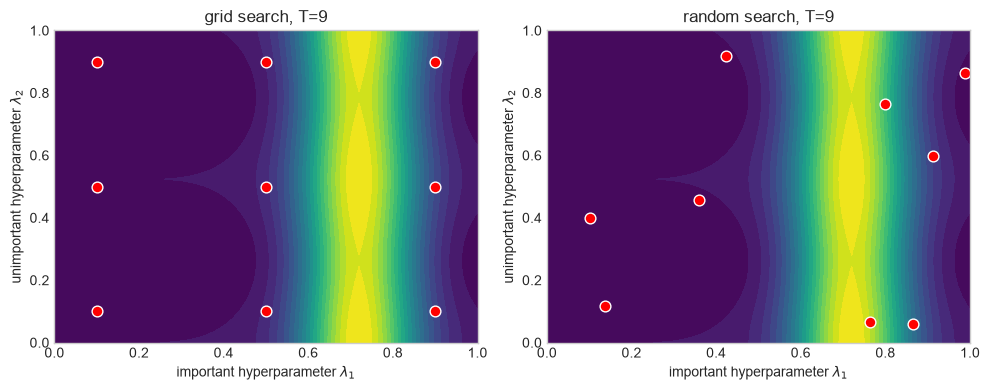

In [54]:
#| echo: false
def toy_objective(l1, l2):
    """Validation loss: depends strongly on l1, weakly on l2. Minimum near l1=0.72."""
    return 1 - np.exp(-((l1 - 0.72) ** 2) / 0.02) + 0.05 * np.sin(6 * l2) ** 2


rng = np.random.default_rng(RANDOM_STATE)
T = 9
side = np.linspace(0.1, 0.9, int(np.sqrt(T)))
G1, G2 = np.meshgrid(side, side)
grid_best = toy_objective(G1, G2).min()

random_best = np.array([
    toy_objective(rng.uniform(0, 1, T), rng.uniform(0, 1, T)).min() for _ in range(1000)
])

print(f"Grid ({T} trials, {len(side)} distinct l1 values): loss = {grid_best:.3f}. Random ({T} trials, {T} distinct l1 values): median loss = {np.median(random_best):.3f}")
print(f"Random search beats the grid in {(random_best < grid_best).mean():.0%} of the repetitions")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
for ax, (title, p1, p2) in zip(axes, [("grid", G1.ravel(), G2.ravel()),
                                      ("random", rng.uniform(0, 1, T), rng.uniform(0, 1, T))]):
    ax.contourf(xx, yy, toy_objective(xx, yy), levels=20, cmap="viridis_r")
    ax.scatter(p1, p2, c="red", edgecolor="white", s=60)
    ax.set_title(f"{title} search, T={T}")
    ax.set_xlabel("important hyperparameter $\\lambda_1$")
    ax.set_ylabel("unimportant hyperparameter $\\lambda_2$")
plt.tight_layout()
plt.show()

# Hands-On: Random Forest Grid versus Random Search

Search a random forest with 48 trees and balanced class weights. 

- Grid: three depths × three leaf sizes.
- Random: nine independently sampled depth/leaf configurations within the declared bounds.

In [55]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rf_pipeline = Pipeline([
    ("preprocess", classification_preprocess),
    ("clf", RandomForestClassifier(n_estimators=48, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=1)),
])
searches = {
    "grid": GridSearchCV(rf_pipeline,
        {"clf__max_depth": [2, 8, 24], "clf__min_samples_leaf": [1, 5, 20]},
        scoring="balanced_accuracy", cv=cv, n_jobs=1, error_score="raise"),
    "random": RandomizedSearchCV(rf_pipeline,
        {"clf__max_depth": randint(2, 25), "clf__min_samples_leaf": randint(1, 21)},
        n_iter=9, scoring="balanced_accuracy", cv=cv, random_state=RANDOM_STATE,
        n_jobs=1, error_score="raise"),
}


In [56]:
#| echo: false
search_rows = []
for name, search in searches.items():
    started_at = time.perf_counter()
    search.fit(X_cls_train, y_cls_train)
    search_rows.append({
        "search": name, "candidates": len(search.cv_results_["params"]),
        "cv_balanced_accuracy": search.best_score_,
        "elapsed_seconds": time.perf_counter() - started_at,
        "validation_balanced_accuracy": evaluate_classifier(search, X_cls_val, y_cls_val)["balanced_accuracy"],
        "best_parameters": search.best_params_,
    })
pd.DataFrame(search_rows)

,search,candidates,cv_balanced_accuracy,elapsed_seconds,validation_balanced_accuracy,best_parameters
0,grid,9,0.823361,4.717536,0.810754,"{'clf__max_depth': 24, 'clf__min_samples_leaf'..."
1,random,9,0.815086,3.642492,0.822780,"{'clf__max_depth': 23, 'clf__min_samples_leaf'..."


# Explain the Search Results

- How many distinct depth and leaf-size values did each method try?
- Are the selected configurations different? If scores tie, are their validation predictions identical?
- Compare CV balanced accuracy, validation balanced accuracy, and elapsed time.
- Why can a coarse grid miss useful intermediate values?

# Extended Demo: Four-Parameter Random Forest Search

Search depth, minimum leaf size, feature fraction per split, and bootstrap sample fraction.

- The grid uses two endpoints per dimension ($2^4=16$ configurations).
- Random search draws 16 configurations, including intermediate settings, on the same bounded domain.

Both use the same folds, learner seed, preprocessing, and balanced-accuracy scorer.

In [ ]:
#| echo: false
rf_extended_pipeline = Pipeline([
    ("preprocess", classification_preprocess),
    ("clf", RandomForestClassifier(n_estimators=64, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=1)),
])
rf_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "clf__max_depth": [2, 24], "clf__min_samples_leaf": [1, 24],
    "clf__max_features": [0.15, 1.0], "clf__max_samples": [0.5, 1.0],
}
param_distributions = {
    "clf__max_depth": randint(2, 25), "clf__min_samples_leaf": randint(1, 25),
    "clf__max_features": uniform(0.15, 0.85), "clf__max_samples": uniform(0.5, 0.5),
}
rf_searches = {
    "grid": GridSearchCV(rf_extended_pipeline, param_grid, cv=rf_cv,
                         scoring="balanced_accuracy", n_jobs=1, error_score="raise"),
    "random": RandomizedSearchCV(rf_extended_pipeline, param_distributions, n_iter=16,
        cv=rf_cv, scoring="balanced_accuracy", n_jobs=1,
        random_state=RANDOM_STATE, error_score="raise"),
}
rf_search_rows = []
for name, search in rf_searches.items():
    started_at = time.perf_counter()
    search.fit(X_cls_train, y_cls_train)
    rf_search_rows.append({
        "search": name, "n_configs": len(search.cv_results_["params"]),
        "elapsed_s": time.perf_counter() - started_at,
        "best_cv_balanced_accuracy": search.best_score_,
        "validation_balanced_accuracy": balanced_accuracy_score(y_cls_val, search.predict(X_cls_val)),
        "best_parameters": search.best_params_,
    })
pd.DataFrame(rf_search_rows).round(4)

,search,n_configs,elapsed_s,best_cv_balanced_accuracy,validation_balanced_accuracy,best_parameters
0,grid,16,13.0215,0.8116,0.8146,"{'clf__max_depth': 24, 'clf__max_features': 1...."
1,random,16,14.0967,0.8201,0.8255,"{'clf__max_depth': 21, 'clf__max_features': 0...."


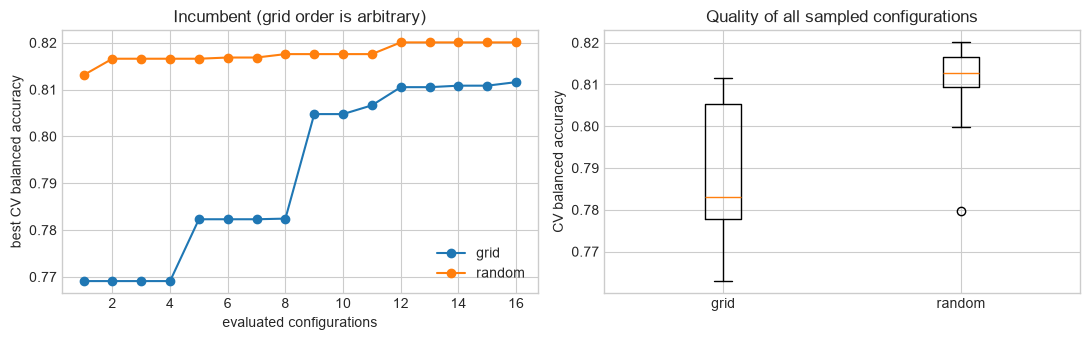

In [ ]:
#| echo: false
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, search in rf_searches.items():
    scores = search.cv_results_["mean_test_score"]
    axes[0].plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores), marker="o", label=name)
axes[0].set(xlabel="evaluated configurations", ylabel="best CV balanced accuracy", title="Incumbent (grid order is arbitrary)")
axes[0].legend()
axes[1].boxplot([search.cv_results_["mean_test_score"] for search in rf_searches.values()],
                tick_labels=list(rf_searches))
axes[1].set(ylabel="CV balanced accuracy", title="Quality of all sampled configurations")
plt.tight_layout()
plt.show()

# Beyond Random Search: Learning Where to Search

Bayesian optimization fits a surrogate to observed configuration/loss pairs and uses an acquisition function to balance exploring uncertain regions with exploiting promising ones [Snoek et al. (2012)](https://arxiv.org/abs/1206.2944).

- SMAC uses random-forest surrogates for algorithm configuration, including categorical and conditional choices [Hutter et al. (2011)](https://doi.org/10.1007/978-3-642-25566-3_40)
    - A random-forest **surrogate** predicts validation loss from hyperparameter settings.
    - This is a different role from the random-forest **classifier** in our demo, which predicts income from input features.
- Evolutionary and local-search approaches instead modify candidate configurations. 

These methods use search history, unlike independent random sampling.

::::{.columns}
:::{.column width="33%"}
![Grid search](https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b6/Hyperparameter_Optimization_using_Grid_Search.svg/1920px-Hyperparameter_Optimization_using_Grid_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail)
:::
:::{.column width="33%"}
![Random search](https://thumb.wikimedia.org/wikipedia/commons/thumb/7/74/Hyperparameter_Optimization_using_Random_Search.svg/1920px-Hyperparameter_Optimization_using_Random_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail)
:::
:::{.column width="33%"}
![Bayesian optimization search](https://thumb.wikimedia.org/wikipedia/commons/thumb/3/3c/Hyperparameter_Optimization_using_Tree-Structured_Parzen_Estimators.svg/1920px-Hyperparameter_Optimization_using_Tree-Structured_Parzen_Estimators.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail)
:::
::::

# Beyond Random Search: Learning Where to Search

![Bayesian optimization search](https://upload.wikimedia.org/wikipedia/commons/0/02/GpParBayesAnimationSmall.gif?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled)

# Bayesian Optimization: Learn the Validation-Loss Surface {.scrollable}

Keep a history $\mathcal H_t=\{(\lambda_i,y_i)\}_{i=1}^t$, where $y_i=f(\lambda_i)+\epsilon_i$ is the observed validation loss.

- A **surrogate** estimates the loss and uncertainty at configurations that have not been evaluated.

A Gaussian process (GP) specifies a prior mean and covariance kernel.

- Conditioning on observations gives a predictive mean $\mu_t(\lambda)$ and standard deviation $\sigma_t(\lambda)$:
- $f(\lambda)\mid\mathcal H_t\sim\mathcal N\!\left(\mu_t(\lambda),\sigma_t^2(\lambda)\right)$

The kernel expresses which configurations should behave similarly. 

- GPs are convenient for small continuous spaces.
- SMAC uses random-forest surrogates to handle mixed and conditional spaces.

Expected improvement (EI) rewards both low predicted loss and uncertainty:

- **Exploitation:** prefer low $\mu_t$ near promising configurations.
- **Exploration:** uncertainty can make an untested region attractive.

# Bayesian Optimization: The Sequential Loop {.scrollable}

1. Evaluate a small initial design, often random configurations.
2. Fit or update the surrogate using observed validation losses.
3. Optimize an acquisition function to propose a configuration.
4. Train and validate that configuration using the fixed protocol.
5. Append the result and repeat until the budget is exhausted.

Return the best **evaluated** configuration, then perform final test evaluation after all choices are frozen.

- The surrogate's predicted optimum is not automatically the selected model. *Why*?
- Bayesian optimization can save expensive evaluations, but surrogate fitting and acquisition optimization add overhead. 

# Demo: Surrogate Uncertainty and the Next Evaluation

The GP sees five observations.

- the true curve is shown only to explain the demonstration.
- Expected improvement uses the GP posterior and observed losses, never the hidden true curve.

The marked point is the next proposed evaluation. After observing its loss, the real loop would refit the GP and recompute EI.

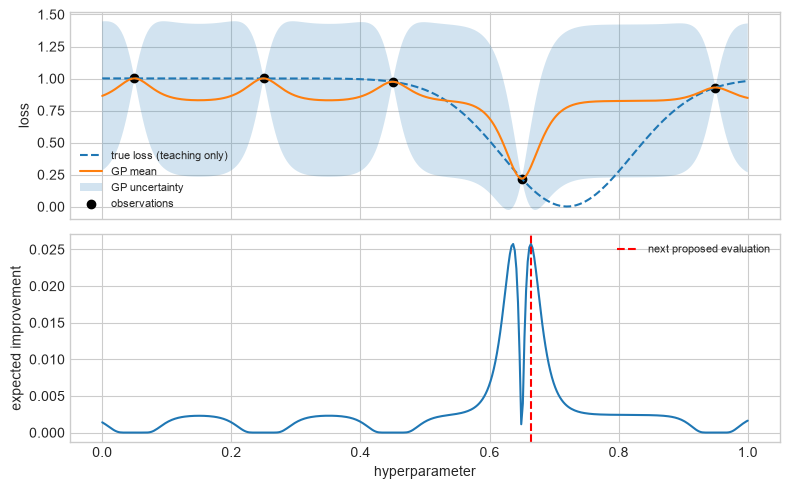

In [ ]:
#| echo: false
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

bo_x = np.array([0.05, 0.25, 0.45, 0.65, 0.95]).reshape(-1, 1)
bo_y = toy_objective(bo_x.ravel(), 0.5)
bo_gp = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0, (0.01, 10)) * Matern(length_scale=0.15, length_scale_bounds=(0.03, 1.0), nu=2.5),
    alpha=1e-6, normalize_y=True, random_state=RANDOM_STATE,
)
bo_gp.fit(bo_x, bo_y)
bo_candidates = np.linspace(0, 1, 400).reshape(-1, 1)
bo_mean, bo_std = bo_gp.predict(bo_candidates, return_std=True)
bo_delta = bo_y.min() - bo_mean - 0.01
bo_z = np.divide(bo_delta, bo_std, out=np.zeros_like(bo_delta), where=bo_std > 0)
bo_ei = np.where(bo_std > 0, bo_delta * norm.cdf(bo_z) + bo_std * norm.pdf(bo_z), np.maximum(bo_delta, 0))
bo_next = int(np.argmax(bo_ei))
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(bo_candidates.ravel(), toy_objective(bo_candidates.ravel(), 0.5), "--", label="true loss (teaching only)")
axes[0].plot(bo_candidates.ravel(), bo_mean, label="GP mean")
axes[0].fill_between(bo_candidates.ravel(), bo_mean - 1.96 * bo_std, bo_mean + 1.96 * bo_std, alpha=0.2, label="GP uncertainty")
axes[0].scatter(bo_x.ravel(), bo_y, color="black", label="observations")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=8)
axes[1].plot(bo_candidates.ravel(), bo_ei)
axes[1].axvline(bo_candidates[bo_next, 0], color="red", linestyle="--", label="next proposed evaluation")
axes[1].set(xlabel="hyperparameter", ylabel="expected improvement")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# The Budget Problem

# The Budget Is Part of the Problem {.scrollable}

Budget:

- A **trial/instance budget** limits the number of candidates.
- A **time budget** limits elapsed time. Include CV folds, preprocessing, search overhead, and final refitting when reporting total cost.

They are different: a deep forest can cost much more than a small linear model. 

For a sequential search history $H_N=\{(\lambda_i,r_i,\widehat f_i,c_i)\}_{i=1}^N$, a simplified resource constraint is

$$\sum_{i=1}^N c(\lambda_i,r_i)+c_{\mathrm{overhead}}+c_{\mathrm{refit}}\le B.$$

Here $r_i$ is fidelity (for example, sample size or epochs), $c$ is cost, and $B$ is the total budget.

- The optimizer chooses what to evaluate, at what fidelity, and when to stop.
- It returns the best observed candidate, rather than a global optimum.

Compare methods with the same data, metric, hardware, and resource accounting.

- Equal trial counts do not imply equal elapsed time.
- Report the requested budget **and measured elapsed time**.

# Spending the Budget: Adaptation and Fidelity

- Adaptive search uses previous evaluations to choose later candidates; Bayesian optimization is one approach. 
- Multi-fidelity search first uses cheaper approximations and then spends more resources on promising candidates.

For example, successive halving repeatedly removes weak candidates while increasing resources for survivors [Li et al. (2018), *Hyperband*](https://www.jmlr.org/papers/v18/16-558.html)

- Combine random configurations with adaptive resource allocation and early stopping.
- The key is to balance exploration and exploitation, and to use the available computational resources effectively.
- Low-fidelity rankings can be misleading: a model that learns slowly may be discarded too early.

# Multi-Fidelity Search

**Fidelity Means Resource Level**: a multi-fidelity strategy evaluates many configurations cheaply, then spends more resources on promising ones.

| Low fidelity | Higher fidelity |
| --- | --- |
| fewer rows | more rows |
| fewer trees | more trees |
| fewer epochs | more epochs |
| shorter training | longer training |

# Successive Halving, Hyperband, and BOHB

[Jamieson and Talwalkar (2016)](https://proceedings.mlr.press/v51/jamieson16.html) study allocating resources to identify promising candidates. In successive halving with reduction factor 3:

| Round | Candidates | Resource per candidate | Total resource |
| --- | --- | --- | --- |
| 0 | 27 | 1 unit | 27 units |
| 1 | 9 | 3 units | 27 units |
| 2 | 3 | 9 units | 27 units |
| 3 | 1 | 27 units | 27 units |

- Hyperband varies the initial breadth/resource tradeoff across halving brackets.
- [BOHB (Falkner et al., 2018)](https://proceedings.mlr.press/v80/falkner18a.html) combines model-based configuration sampling with Hyperband-style allocation. 
    - Constant work per round is an idealization: actual training cost need not grow linearly with resource.

# Multi-Fidelity and Combined Search: Research Figures

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-1.png)

Low fidelity is useful when it preserves enough of the high-fidelity ranking. It can also discard slow-starting or data-hungry models.

# Multi-Fidelity and Combined Search: Research Figures

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-2.png)

# Multi-Fidelity and Combined Search: Research Figures

![Regret against wall-clock time in the cited BOHB experiments. Source: Falkner et al. via the Hutter and Vanschoren tutorial.](img/fidelity-3.png)

The BOHB figure illustrates the anytime/final-performance tradeoff in those experiments.

# Demo: Successive Halving on the Same Random Forest Space

Use the same four forest hyperparameters and balanced-accuracy scorer.

In [ ]:
halving = HalvingRandomSearchCV(
    rf_extended_pipeline, param_distributions,
    n_candidates=27, factor=3,
    resource="n_samples", min_resources=min(300, max(30, len(X_cls_train) // 9)),
    cv=rf_cv, scoring="balanced_accuracy", n_jobs=1, random_state=RANDOM_STATE,
)
started_at = time.time()
halving.fit(X_cls_train, y_cls_train)
halving_elapsed = time.time() - started_at

In [61]:
#| echo: false
rf_search_rows.append({
    "search": "successive halving",
    "n_configs": halving.n_candidates_[0],
    "cv_evaluations": len(halving.cv_results_["params"]),
    "elapsed_s": halving_elapsed,
    "best_cv_balanced_accuracy": halving.best_score_,
    "validation_balanced_accuracy": balanced_accuracy_score(y_cls_val, halving.predict(X_cls_val)),
})
for row in rf_search_rows[:-1]:
    row["cv_evaluations"] = row["n_configs"]
pd.DataFrame({"iteration": range(halving.n_iterations_), "candidates": halving.n_candidates_, "rows_per_candidate": halving.n_resources_})

,iteration,candidates,rows_per_candidate
0,0,27,300
1,1,9,900
2,2,3,2700


In [62]:
pd.DataFrame(rf_search_rows).round(4)

,search,n_configs,elapsed_s,best_cv_balanced_accuracy,validation_balanced_accuracy,best_parameters,cv_evaluations
0,grid,16,13.0215,0.8116,0.8146,"{'clf__max_depth': 24, 'clf__max_features': 1....",16
1,random,16,14.0967,0.8201,0.8255,"{'clf__max_depth': 21, 'clf__max_features': 0....",16
2,successive halving,27,11.2670,0.8162,0.8174,NaN,39


# Budget Questions

1. How many initial configurations and how many candidate/fidelity evaluations did halving use?
2. How do its actual runtime and validation score compare with grid/random search?
3. Which random-forest hyperparameters increase training cost?
4. When could early rankings on a small sample discard the eventual best candidate?
5. Why does the grid's arbitrary enumeration order affect its anytime curve?

# AutoML and CASH

# What Is AutoML?

**Automated Machine Learning (AutoML)** automates choices in constructing and evaluating an ML solution, within a user-defined task, search space, metric, and budget. 

- HPO fixes the learning algorithm and tunes its settings.
- AutoML can also choose the algorithm and parts of the pipeline.
- Humans still define success, admissible data, evaluation design, and operational constraints.

# CASH: Combined Algorithm Selection and Hyperparameter Optimization

Let $\mathcal A=\{A_1,\ldots,A_M\}$ be candidate algorithms and $\Lambda_a$ the hyperparameter space of $A_a$. The **CASH** problem is

$$ (a^*,\lambda^*)\in\arg\min_{a\in\{1,\ldots,M\},\;\lambda\in\Lambda_a}
\frac{1}{K}\sum_{k=1}^{K}\mathcal L_{D_k}\!\left(A_{a,\lambda}(D_{-k})\right). $$

Its domain is a conditional union $\bigcup_a\{a\}\times\Lambda_a$, rather than one rectangular grid.

- A **root hyperparameter** selects the learner, activating only its associated space $\Lambda_a$.
- E.g., A forest activates tree-related settings; logistic regression activates regularization settings. 

A practical solver approximates this objective under a resource budget.

[Thornton et al. (2013), *Auto-WEKA: Combined Selection and Hyperparameter Optimization of Classification Algorithms*](https://arxiv.org/abs/1208.3719) introduced this formulation.

- CASH is the algorithm-selection problem; computation caching is a separate implementation technique.

# Two AutoML Systems: auto-sklearn and FLAML

| System | Main ideas in the cited paper |
| --- | --- | 
| [auto-sklearn (2015)](https://papers.neurips.cc/paper_files/paper/2015/hash/11d0e6287202fced83f79975ec59a3a6-Abstract.html) | Bayesian optimization of scikit-learn pipelines, meta-learning from earlier datasets, ensemble construction |
| [FLAML (2021)](https://arxiv.org/abs/1911.04706) | Cost-aware learner selection, hyperparameter search, and sample-size allocation | 

# FLAML: What Makes Search Economical?

FLAML coordinates learner selection with the cost and expected benefit of further search.

- Low-cost initial configurations and cost-related settings help it start cheaply, while sample size can serve as another resource dimension.
- [Cost-Frugal Optimization (CFO), Wu et al. (2021)](https://ojs.aaai.org/index.php/AAAI/article/view/17239) uses randomized local search starting from inexpensive configurations.
- [BlendSearch, Wang et al. (2021)](https://www.microsoft.com/en-us/research/publication/economical-hyperparameter-optimization-with-blended-search-strategy/) blends local and global search. 

# auto-sklearn versus FLAML

| Aspect | auto-sklearn | FLAML |
| --- | --- | --- |
| Search scope | Learners and preprocessing in a fixed template | Learners and their conditional settings in our example |
| Optimization | SMAC-based Bayesian optimization | Cost-frugal local search / BlendSearch |
| Prior knowledge | Meta-learning and initial portfolios | Low-cost initial configurations |
| Resource allocation | Successive halving in version 2.0 | Cost-aware learner choice and sample-size allocation |
| Typical output | Ensemble of evaluated pipelines | Best model; optional ensembling |

# FLAML for Classification {.scrollable}

In [63]:
classification_automl = AutoML()
classification_started_at = time.perf_counter()
classification_automl.fit(
    X_train=X_cls_train_flaml, y_train=y_cls_train,
    X_val=X_cls_val_flaml, y_val=y_cls_val,
    eval_method="holdout",
    retrain_full=False,
    estimator_list=CLASSIFIERS, # ["rf", "extra_tree", "lrl2"]
    n_jobs=1,
    task="classification", metric=flaml_balanced_accuracy,
    time_budget=time_budget,
    log_file_name=f"flaml_main_classification_balanced_accuracy_{time_budget}s.log",
    seed=RANDOM_STATE, verbose=1,
)
classification_elapsed = time.perf_counter() - classification_started_at
print(f"Best estimator: {classification_automl.best_estimator}")
print(f"Best validation loss: {classification_automl.best_loss:.6f}")
print(f"Training time for best config: {classification_automl.best_config_train_time:.3f}s")

Best estimator: rf
Best validation loss: 0.210733
Training time for best config: 0.227s


# FLAML for Classification {.scrollable}

In [64]:
classification_automl_scores = evaluate_classifier(classification_automl, X_cls_val_flaml, y_cls_val)
# print("confusion matrix:")
# print(confusion_matrix(y_cls_val, classification_automl.predict(X_cls_val_flaml)))
pd.DataFrame(
    [classification_baseline_scores, classification_automl_scores],
    index=["manual_baseline", "flaml"],
).round(3)

,accuracy,balanced_accuracy,f1
manual_baseline,0.866,0.775,0.685
flaml,0.873,0.789,0.706


# CASH Search Spaces Are Conditional

The representation is a conditional tree or graph, not an unrestricted Cartesian product of every learner's settings.

- Inactive coordinates do not define different effective models.


| Learner selected at the root | Active hyperparameters | Inactive examples |
| --- | --- | --- |
| Random forest | tree count, tree/leaf constraints | logistic regularization strength |
| Logistic regression | penalty and regularization strength | forest depth and number of trees |
| Gradient boosting | learning rate, iterations, tree constraints | unrelated learners' settings |

CASH inherits HPO's expensive evaluations and adds learner-level allocation: **which algorithm deserves the next unit of budget?**

- Different learners and configurations have different costs; the answer should depend on observed quality, cost, and remaining resources.

# Inspect FLAML's Conditional CASH Space


In [65]:
from flaml.automl.model import RandomForestEstimator
from flaml.automl.task.factory import task_factory
print("Allowed learners:", CLASSIFIERS)

Allowed learners: ['rf', 'extra_tree', 'lrl2']


In [66]:
#| echo: false
def describe_space(space):
    rows = []
    for name, spec in space.items():
        domain = spec["domain"]
        if hasattr(domain, "categories"): values = str(list(domain.categories))
        elif hasattr(domain, "lower") and hasattr(domain, "upper"):
            sampler = domain.get_sampler() if hasattr(domain, "get_sampler") else None
            values = f"[{domain.lower}, {domain.upper}] ({type(sampler).__name__})"
        else: values = str(domain)
        rows.append({"hyperparameter": name, "domain": values, "init_value": spec.get("init_value"), "low_cost_init_value": spec.get("low_cost_init_value")})
    return pd.DataFrame(rows)

In [67]:
describe_space(RandomForestEstimator.search_space(data_size=X_cls_train_flaml.shape, task=task_factory("classification", X_cls_train_flaml, y_cls_train)))

,hyperparameter,domain,init_value,low_cost_init_value
0,n_estimators,"[4, 2048] (_LogUniform)",4.000000,4.0
1,max_features,"[0.1, 1.0] (_LogUniform)",0.267261,NaN
2,max_leaves,"[4, 2400] (_LogUniform)",4.000000,4.0
3,criterion,"['gini', 'entropy']",NaN,NaN


# Anytime Performance Under a Budget

For completed trials with validation losses $f_i$ and completion times $t_i$, define the incumbent curve

$$f^*(\tau)=\min\{f_i:t_i\le\tau\},\qquad \tau\le B.$$

- Plotting this curve against elapsed time reveals how quickly an optimizer becomes useful; plotting against trial count answers a different question.
- Budget can also mean CPU/GPU hours, money, or energy.

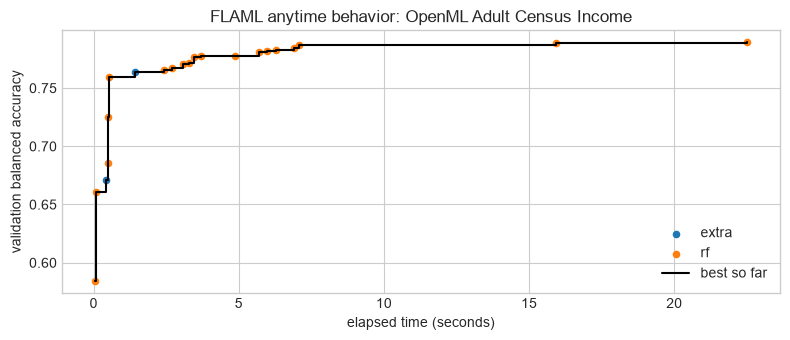

In [68]:
#| echo: false
from flaml.automl.data import get_output_from_log
log_path = f"flaml_main_classification_balanced_accuracy_{time_budget}s.log"
time_history, best_loss_history, loss_history, config_history, _ = get_output_from_log(
    filename=log_path, time_budget=float("inf")
)
learners = [record["Current Learner"] for record in config_history]
fig, ax = plt.subplots(figsize=(8, 3.5))
for learner in sorted(set(learners)):
    idx = [i for i, name in enumerate(learners) if name == learner]
    ax.scatter(np.asarray(time_history)[idx], 1 - np.asarray(loss_history)[idx], s=20, label=learner)
ax.step(time_history, 1 - np.asarray(best_loss_history), where="post", color="black", label="best so far")
ax.set(xlabel="elapsed time (seconds)", ylabel="validation balanced accuracy", title=f"FLAML anytime behavior: {adult_source}")
ax.legend()
plt.tight_layout()
plt.show()

# Interpreting the Budget Experiment

Increasing a budget changes the search opportunity, not the task definition.

- Explain the observed tradeoff using validation quality, elapsed time, and selected estimator.
- If two budgets give similar validation scores, discuss whether the extra compute is justified.

A system that is excellent after two hours may not be the best choice for an interactive workflow that allows only two minutes.

# Comparing Classification Objectives

Run the same learner list and budget with accuracy, balanced accuracy, and F1. Compare validation scores; fix the objective before using test data.

In [69]:
#| echo: false
def run_flaml_classification(metric="balanced_accuracy", time_budget=time_budget):
    model = AutoML()
    started_at = time.time()
    model.fit(
        X_train=X_cls_train_flaml,
        y_train=y_cls_train,
        X_val=X_cls_val_flaml,
        y_val=y_cls_val,
        eval_method="holdout",
        retrain_full=False,
        estimator_list=CLASSIFIERS,
        n_jobs=1,
        task="classification",
        metric=flaml_balanced_accuracy if metric == "balanced_accuracy" else metric,
        time_budget=time_budget,
        log_file_name=f"flaml_adult_{metric}_{time_budget}s.log",
        seed=RANDOM_STATE,
        verbose=0,
    )
    elapsed = time.time() - started_at
    scores = evaluate_classifier(model, X_cls_val_flaml, y_cls_val)
    return {
        "metric": metric,
        "budget": time_budget,
        "elapsed": elapsed,
        "best_estimator": model.best_estimator,
        "best_loss": model.best_loss,
        **scores,
    }


classification_metric_results = pd.DataFrame(
    [run_flaml_classification(metric=m, time_budget=time_budget) for m in ["accuracy", "balanced_accuracy", "f1"]]
)
classification_metric_results.round(3)

,metric,budget,elapsed,best_estimator,best_loss,accuracy,balanced_accuracy,f1
0,accuracy,30,29.992,rf,0.120,0.880,0.787,0.711
1,balanced_accuracy,30,30.001,rf,0.211,0.873,0.789,0.706
2,f1,30,30.015,rf,0.311,0.870,0.775,0.689


# Classification Questions

1. Which metric selected the strongest model for balanced accuracy?
2. Which metric selected the strongest model for F1?
3. Which errors are more costly in this task?
4. What additional fairness or governance checks would you run before deployment?

# Regression Dataset: California Housing

The task is to predict median house value for California districts from demographic and geographic attributes.

In [76]:
#| echo: false
def load_housing_data():
    try:
        housing = fetch_california_housing(as_frame=True)
        return housing.frame.copy(), "California Housing"
    except Exception as exc:
        print(f"Could not download California Housing: {exc}")
        print("Falling back to the real built-in diabetes regression dataset.")
        diabetes = load_diabetes(as_frame=True)
        df = diabetes.frame.copy()
        df = df.rename(columns={"target": "MedHouseVal"})
        return df, "scikit-learn diabetes fallback"

In [75]:
housing_df, housing_source = load_housing_data()
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [71]:
#| echo: false
regression_target = "MedHouseVal" if "MedHouseVal" in housing_df.columns else "target"
X_reg = housing_df.drop(columns=[regression_target])
y_reg = housing_df[regression_target]

X_reg_dev, X_reg_test, y_reg_dev, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg_dev, y_reg_dev, test_size=0.25, random_state=RANDOM_STATE
)

X_reg_val_flaml, _ = prepare_flaml_frame(X_reg_val, categorical_columns=[])
X_reg_train_flaml, _ = prepare_flaml_frame(X_reg_train, categorical_columns=[])
X_reg_test_flaml, _ = prepare_flaml_frame(X_reg_test, categorical_columns=[])

# Manual Regression Baselines

We compare FLAML against two common baselines:

- Ridge regression: simple, fast, and linear.
- Random forest: nonlinear and stronger, but less transparent and more expensive.

In [72]:
ridge_baseline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=1.0)),
    ]
)
forest_baseline = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1,)
ridge_baseline.fit(X_reg_train, y_reg_train)
forest_baseline.fit(X_reg_train, y_reg_train)
ridge_scores = evaluate_regressor(ridge_baseline, X_reg_val, y_reg_val)
forest_scores = evaluate_regressor(forest_baseline, X_reg_val, y_reg_val)
pd.DataFrame([ridge_scores, forest_scores], index=["ridge", "random_forest"]).round(3)

,rmse,mae,r2
ridge,0.728,0.533,0.614
random_forest,0.508,0.333,0.812


# FLAML for Regression

In [73]:
regression_automl = AutoML()
regression_started_at = time.perf_counter()
regression_automl.fit(
    X_train=X_reg_train_flaml, y_train=y_reg_train,
    X_val=X_reg_val_flaml, y_val=y_reg_val,
    eval_method="holdout",
    retrain_full=False,
    estimator_list=REGRESSORS,
    n_jobs=1,
    task="regression", metric="rmse", # RMSE, MAE, or R2
    time_budget=time_budget,
    log_file_name=f"flaml_main_regression_rmse_{time_budget}s.log",
    seed=RANDOM_STATE, verbose=1,
)
regression_elapsed = time.perf_counter() - regression_started_at
regression_automl_scores = evaluate_regressor(regression_automl, X_reg_val_flaml, y_reg_val)
pd.DataFrame([ridge_scores, forest_scores, regression_automl_scores], index=["ridge", "random_forest", "flaml"],).round(3)

,rmse,mae,r2
ridge,0.728,0.533,0.614
random_forest,0.508,0.333,0.812
flaml,0.500,0.338,0.818


# Budget Experiment

In [74]:
#| echo: false
def run_flaml_regression(time_budget=time_budget, metric="rmse"):
    model = AutoML()
    started_at = time.time()
    model.fit(
        X_train=X_reg_train_flaml,
        y_train=y_reg_train,
        X_val=X_reg_val_flaml,
        y_val=y_reg_val,
        eval_method="holdout",
        retrain_full=False,
        estimator_list=REGRESSORS,
        n_jobs=1,
        task="regression",
        metric=metric,
        time_budget=time_budget,
        log_file_name=f"flaml_housing_{metric}_{time_budget}s.log",
        seed=RANDOM_STATE,
        verbose=0,
    )
    elapsed = time.time() - started_at
    scores = evaluate_regressor(model, X_reg_val_flaml, y_reg_val)
    return {
        "budget": time_budget,
        "metric": metric,
        "elapsed": elapsed,
        "best_estimator": model.best_estimator,
        "best_loss": model.best_loss,
        **scores,
    }


regression_budget_results = pd.DataFrame(
    [run_flaml_regression(time_budget=b, metric="rmse") for b in budget_values]
)
regression_budget_results.round(3)

,budget,metric,elapsed,best_estimator,best_loss,rmse,mae,r2
0,5,rmse,5.007,rf,0.574,0.574,0.413,0.760
1,15,rmse,14.745,rf,0.507,0.507,0.346,0.813
2,30,rmse,30.755,rf,0.500,0.500,0.338,0.818


# From CASH to End-to-End Pipeline Optimization {.scrollable}

So far, we fixed data cleaning, category encoding, feature availability, and validation design, then searched over learners. 

- End-to-end pipeline optimization also searches over the **structure and operations** that turn raw data into predictions.

Let $s$ denote a pipeline structure, $\theta\in\Theta_s$ its conditional settings, and $\mathcal S(C)$ the structures allowed by human constraints $C$:

$$ (s^*,\theta^*)\in\arg\min_{s\in\mathcal S(C),\;\theta\in\Theta_s}
\widehat{\mathcal L}_{\mathrm{val}}\!\left(\operatorname{Fit}(P_{s,\theta},D_{\mathrm{tr}})\right),
\qquad c_{\mathrm{search}}\le B. $$

The pipeline may choose 

- imputation → encoding → feature construction/selection → resampling → learner → calibration. 
- Structure can be a sequence or a graph; changing an early step changes the meaning and cost of later choices.

# Why Full Pipeline Search Is Harder {.scrollable}

- **Dependencies:** scaling matters for some learners; SMOTE must follow a suitable representation and stay inside training folds.
- **Data quality:** deletion, imputation, and feature construction can change who is represented and what the model learns.
- **Constraints:** accuracy competes with latency, fairness, interpretability, and resource limits; some pipelines are inadmissible even if accurate.
- **Evaluation:** more trials increase validation overfitting; learned transformations must be refitted inside each training split.
- **Control and provenance:** record data versions, transformations, constraints, code, and failures so humans can understand and revise a result.

Even before selecting operators, allowing each of $s$ step types at most once gives $\sum_{m=0}^{s} s!/(s-m)!$ ordered structures: 326 when $s=5$. 

- This is an illustrative unrestricted count; type and domain constraints remove many structures.
- Scaling before a tree is often unnecessary, rather than invalid. 

# Preprocessing Order Is a Search Decision

[@giovanelli2021effective] study transformations and combinations of transformations as **pipeline prototypes**.

Distinguish three decisions:

1. **Structure:** which step types are present and in which order.
2. **Operators:** which implementation fills each step.
3. **Hyperparameters:** how each operator and learner is configured.

**Exercise:** propose two admissible orders for feature selection and resampling, identify assumptions, and explain how you would compare them.

# HAMLET: Human Knowledge Shapes the Search {.scrollable}

[@francia2023hamlet] connect AutoML with explicit human knowledge and constraints.

- The data scientist expresses constraints in a logical knowledge base, represented through a Problem Graph.
- Structured argumentation makes conflicts between rules and pipeline choices explicit when deriving the admissible search space. 

The question shifts from “Which model won?” to “Which alternatives were allowed, and why?” 

- An iterative workflow makes the human role concrete: encode rules → derive an admissible space → search → inspect evidence → revise rules.
- Separate data (forbidden features) and ordering (which preprocessing step may follow another) cosntraints, and learner requirements (such as suitable scaling for distance-based methods).

# MLZero: Agents Build and Repair ML Workflows {.scrollable}

[@fang2025mlzero] uses LLM-powered agents to automate workflows across data modalities.

- A perception module turns raw multimodal inputs into task context.
- Agents generate code, execute it, inspect failures, and revise the workflow.
- Semantic memory supplies reusable knowledge, while episodic memory retains earlier attempts and errors to help reduce hallucinated or outdated API calls.

This expands the action space beyond choosing values in a prewritten estimator configuration: agents generate and revise executable workflows. 

**Discussion:** if an agent writes preprocessing code for Adult Income, which execution checks and independent validation would detect leakage, invalid assumptions, or an apparently successful but wrong solution?

# AGE-ML: Specifications for Data-Centric AutoML

[@matteini2026agentic] present a specification-driven architecture.

- Human-readable assumptions, constraints, evaluation criteria, and preferences define a pipeline search space
- An LLM agent loop generates and validates pipelines and provides structured explanations.

**Discussion:** write a specification for our classification task: target, permitted features, missing-value policy, split protocol, objective, budget, and explanation requirements. Which parts could a validator check automatically?

# Compare the Boundaries of Automation {.scrollable}

| Approach | What can change? | What should the human inspect? |
| --- | --- | --- |
| HPO | Hyperparameters of a fixed learner | Bounds, sampling distributions, evaluation |
| CASH / our FLAML example | Learner and its hyperparameters | Learner list, budget allocation, selected configuration |
| Full pipeline search | Preprocessing, features, structure, learner | Leakage, admissible operations, constraints |
| HAMLET | Search space informed by knowledge and argumentation | Rules, Problem Graph, revisions |
| MLZero | Agent-generated and iteratively repaired workflows | Generated code, execution evidence, validation |
| AGE-ML | Pipelines generated from explicit specifications | Specification compliance, provenance, explanations |

Also compare the risks: 

- fixed search spaces can exclude useful solutions;
- rule-based systems require knowledge engineering;
- code-generating agents need execution checks;
- specification-driven systems depend on the quality of the specification. 

Which evidence and human controls would you require in a lending application?

# Pipeline Questions

1. Which requirements constrain the data, and which constrain the model or evaluation?
2. Which proxies could retain information about an excluded attribute?
4. What would an agent need to inspect to generate a valid pipeline without leakage?
5. How would experiment tracking show that a pipeline complied with its specification?

# Design Exercise: Automate One More Decision

Starting from our FLAML example, choose one currently manual operation: missing-value handling, encoding, feature selection, or resampling.

1. Define two admissible alternatives and their conditional parameters.
2. Explain how each alternative is fitted without leaking validation data.
3. State a metric, a total budget, and one human constraint.
4. Specify the evidence needed to accept, explain, and reproduce the selected pipeline.

A design and pseudocode are sufficient; implementing an agent system is outside this lab's practical scope.

# Wrap-Up

# What AutoML Automates

AutoML can automate repetitive parts of modeling:

- trying candidate learners;
- allocating trials;
- tuning hyperparameters;
- returning a strong baseline.

# What AutoML Does Not Automate

AutoML does not remove the data-science responsibility for:

- problem formulation;
- target definition;
- leakage checks;
- fairness assessment;
- deployment monitoring;
- deciding whether a model should be used at all.

A good AutoML report explains both the machine-selected model and the human choices that shaped the search.

# References